# R-GCN-GAE — Complete A-to-Z (Fresh Training → Approach B Validation → Testing)

This notebook trains a **new relational GCN graph autoencoder** using categorical `e_type=` edge relation columns, then validates and tests with exactly the same **Approach B** graph splits, scoring candidates, normal-only checkpoint selection and FPR-constrained threshold protocol as GraphSAGE-GAE and GINE-GAE.

- **Training:** 8,946 normal scenarios; 40 epochs, from scratch.
- **Validation:** 722 normal + 556 attack scenarios. Choose checkpoint from normal-only loss, then select score and threshold from mixed validation while keeping validation FPR at most 5%.
- **Locked testing:** 1,112 normal + 1,444 attack scenarios.
- **Output:** `MyDrive/GNN/Models/RGCN/{training,validation,testing,reports}`. Existing GraphSAGE and GINE runs are not modified.

**Important:** Relation-type `e_type=` columns must be exactly one-hot for every edge; notebook stops if this is not true. Features `node_label` and `scenario_is_attack` are never model input. This is still exploratory evaluation because source scenarios were previously inspected. Do not select based on test metrics.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys, json, time, importlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# -------- CHANGE ONLY IF YOU WANT A NEW, SEPARATE EXPERIMENT NAME --------
# To repeat training, specify a different OUT directory; do not overwrite this run.
MAX_VALIDATION_FPR = 0.05
KNN_K = 5
EPOCHS = 40
SEED = 42

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Local environment: Google Drive mount skipped')

# Locate Approach B datasets anywhere under MyDrive/GNN (including nested folders).
GNN_ROOT = Path('/content/drive/MyDrive/GNN')
SEARCH_ROOTS = [GNN_ROOT] if GNN_ROOT.is_dir() else [Path('/mnt/data'), Path.cwd()]
DATASET_NAMES = {
    'train': 'graphs_b1_train_v6v2.npz',
    'validation': 'graphs_b1_validation_v6v2.npz',
    'normal_test': 'graphs_b1_test_normal_v6v2.npz',
    'attack_test': 'graphs_b1_test_attack_v6v2.npz',
}

def locate(filename):
    matches = sorted({p.resolve() for root in SEARCH_ROOTS for p in root.rglob(filename) if p.is_file()})
    if len(matches) == 0:
        raise FileNotFoundError(f"Cannot find {filename} inside {SEARCH_ROOTS}. Verify filename and upload location.")
    if len(matches) > 1:
        print(f"Multiple copies found for {filename}:")
        for p in matches: print("   ", p)
        raise RuntimeError("Ambiguous dataset copies. Set explicit paths or retain one authoritative copy; do not guess.")
    return matches[0]

paths = {key: locate(filename) for key, filename in DATASET_NAMES.items()}
ROOT = Path('/content/drive/MyDrive/GNN') if Path('/content/drive/MyDrive/GNN').is_dir() else paths['train'].parent
OUT = ROOT / 'Models' / 'RGCN'
TRAIN_DIR, VAL_DIR, TEST_DIR, REPORT_DIR = [OUT / p for p in ['training', 'validation', 'testing', 'reports']]
CKPT = TRAIN_DIR / 'checkpoints'
# Fail closed: a second full Run All must NEVER overwrite an existing experiment.
if OUT.exists() and (OUT / 'training' / 'checkpoints').exists() and any(CKPT.glob('epoch_*.pt')):
    raise FileExistsError(f'Existing run found at {OUT}. To train again, use a NEW OUT directory. Do not delete prior results.')
for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR, REPORT_DIR, CKPT]:
    folder.mkdir(parents=True, exist_ok=True)
os.chdir(OUT)
print('FULL FRESH TRAINING (NOT REUSE)')
print('New output directory:', OUT)
for k,v in paths.items(): print(k, '->', v)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FULL FRESH TRAINING (NOT REUSE)
New output directory: /content/drive/MyDrive/GNN/Models/RGCN
train -> /content/drive/MyDrive/GNN/Stage 4 /graphs_b1_train_v6v2.npz
validation -> /content/drive/MyDrive/GNN/Stage 4 /graphs_b1_validation_v6v2.npz
normal_test -> /content/drive/MyDrive/GNN/Stage 4 /graphs_b1_test_normal_v6v2.npz
attack_test -> /content/drive/MyDrive/GNN/Stage 4 /graphs_b1_test_attack_v6v2.npz


## 1. R-GCN relational model and shared helpers

The R-GCN encoder uses a separate learned transformation for every relation type (`e_type=...`). Other edge attributes are reconstructed through the shared edge decoder; they are **not** fed into R-GCN message passing. The decoder, negative-edge sampling, embedding pooling, scoring, metrics, and Approach B split remain aligned with the earlier model notebooks.


In [3]:
%%writefile stage5_utils.py
"""Stage 5 - shared helpers (NumPy / pandas / SciPy only, no PyTorch).

Used by every Stage 5 model notebook (GraphSAGE-GAE, R-GCN-GAE, R-GCN-GAE) so the data loading, scoring,
thresholds, metrics and suspicious-path extraction are identical for all models.

The ground-truth label is NEVER an input of a model. `is_attack` and `node_label` are read only to build the
validation / test sets and to evaluate.
"""
import os
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

BUCKETS = ("train", "validation", "test_normal", "test_attack")


# --------------------------------------------------------------------------- data
class Bucket:
    """All graphs of one Stage 4 bucket file, kept as flat arrays (one npz = many graphs)."""

    def __init__(self, path):
        z = np.load(path, allow_pickle=False)
        d = {k: z[k] for k in z.files}                     # read every array once
        self.x = d["x"].astype(np.float32)
        self.node_ptr = d["node_ptr"].astype(np.int64)
        self.edge_index = d["edge_index"].astype(np.int64)
        self.edge_attr = d["edge_attr"].astype(np.float32)
        self.edge_ptr = d["edge_ptr"].astype(np.int64)
        self.scenario_id = d["scenario_id"].astype(np.int64)
        self.is_attack = d["scenario_is_attack"].astype(np.int64)
        self.node_label = d["node_label"].astype(np.int64)
        self.feature_names = [str(s) for s in d["feature_names"]]
        self.feature_groups = [str(s) for s in d["feature_groups"]]
        self.edge_feature_names = [str(s) for s in d["edge_feature_names"]]
        self.n = len(self.scenario_id)
        self.n_nodes = np.diff(self.node_ptr)
        self.n_edges = np.diff(self.edge_ptr)              # directed edges (both directions stored)


def feature_columns(bucket, use_component=False, drop_prefixes=()):
    """Indices of the node features a model may use. Component 1 / 2 outputs are a separate group."""
    cols = []
    for i, (n, g) in enumerate(zip(bucket.feature_names, bucket.feature_groups)):
        if g == "component" and not use_component:
            continue
        if any(n.startswith(p) for p in drop_prefixes):
            continue
        cols.append(i)
    return np.array(cols, dtype=np.int64)


def make_batch_np(b, idx, cols):
    """Join graphs idx[0], idx[1], ... into one disjoint graph (node numbers shifted)."""
    xs, eis, eas, bvec, counts = [], [], [], [], []
    off = 0
    for k, i in enumerate(idx):
        n0, n1 = b.node_ptr[i], b.node_ptr[i + 1]
        e0, e1 = b.edge_ptr[i], b.edge_ptr[i + 1]
        xs.append(b.x[n0:n1][:, cols])
        eis.append(b.edge_index[:, e0:e1] + off)
        eas.append(b.edge_attr[e0:e1])
        bvec.append(np.full(n1 - n0, k, dtype=np.int64))
        counts.append(n1 - n0)
        off += n1 - n0
    counts = np.array(counts, dtype=np.int64)
    starts = np.concatenate([[0], np.cumsum(counts)[:-1]])
    bv = np.concatenate(bvec)
    return {"x": np.concatenate(xs), "edge_index": np.concatenate(eis, axis=1), "edge_attr": np.concatenate(eas, axis=0),
            "batch": bv, "node_start": starts[bv], "node_count": counts[bv], "n_graphs": len(idx), "counts": counts}


# --------------------------------------------------------------------------- metrics
def auc(neg, pos):
    """ROC-AUC with 'higher score = more anomalous'; neg = normal scores, pos = attack scores."""
    neg, pos = np.asarray(neg, float), np.asarray(pos, float)
    r = pd.Series(np.concatenate([neg, pos])).rank(method="average").to_numpy()
    n0, n1 = len(neg), len(pos)
    return float((r[n0:].sum() - n1 * (n1 + 1) / 2) / (n0 * n1))


def metrics_at(neg, pos, thr):
    """Decision rule: score > thr  ->  ANOMALOUS."""
    neg, pos = np.asarray(neg, float), np.asarray(pos, float)
    tp, fn = int((pos > thr).sum()), int((pos <= thr).sum())
    fp, tn = int((neg > thr).sum()), int((neg <= thr).sum())
    recall = tp / max(tp + fn, 1)
    fpr = fp / max(fp + tn, 1)
    precision = tp / (tp + fp) if tp + fp else float("nan")
    f1 = 2 * precision * recall / (precision + recall) if tp and precision == precision else 0.0
    acc = (tp + tn) / (tp + fn + fp + tn)
    return {"threshold": float(thr), "recall": recall, "fpr": fpr, "precision": precision, "f1": f1, "accuracy": acc,
            "tp": tp, "fn": fn, "fp": fp, "tn": tn, "auc": auc(neg, pos)}


def threshold_from_normal(normal_scores, percentile=95.0):
    """Threshold set ONLY from held-out normal graphs: the score below which `percentile` % of them fall."""
    return float(np.percentile(np.asarray(normal_scores, float), percentile))


# --------------------------------------------------------------------------- nearest-neighbour scoring
class KNNScorer:
    """Anomaly score = mean distance to the k nearest NORMAL training embeddings (standardised)."""

    def __init__(self, train_emb, k=5):
        self.mu = train_emb.mean(0)
        self.sd = train_emb.std(0)
        self.sd[self.sd < 1e-6] = 1.0
        self.tree = cKDTree((train_emb - self.mu) / self.sd)
        self.k = k

    def score(self, emb):
        d, _ = self.tree.query((emb - self.mu) / self.sd, k=self.k)
        return d.mean(axis=1)


def bag_of_events(b, cols):
    """Graph summary without any structure: mean and max of the node features (a simple baseline)."""
    out = np.zeros((b.n, 2 * len(cols)), dtype=np.float32)
    for i in range(b.n):
        x = b.x[b.node_ptr[i]:b.node_ptr[i + 1]][:, cols]
        out[i] = np.concatenate([x.mean(0), x.max(0)])
    return out


# --------------------------------------------------------------------------- suspicious path
def extract_path(b, i, node_err, edge_err, node_thr, edge_thr, max_nodes=12):
    """For graph i: take the nodes / edges whose error is above the thresholds (set from normal graphs),
    join them into connected groups, and return the group with the largest total error as the suspicious path
    (nodes in time order, because Stage 4 stores nodes in time order)."""
    n0, n1 = b.node_ptr[i], b.node_ptr[i + 1]
    e0, e1 = b.edge_ptr[i], b.edge_ptr[i + 1]
    n = n1 - n0
    ne = node_err[n0:n1]
    ei = b.edge_index[:, e0:e1]
    half = (e1 - e0) // 2                                   # first half = one direction of every edge
    pair_err = 0.5 * (edge_err[e0:e0 + half] + edge_err[e0 + half:e1])
    hi_nodes = np.where(ne > node_thr)[0]
    hi_edges = np.where(pair_err > edge_thr)[0]
    parent = list(range(n))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for k in hi_edges:
        a, c = find(int(ei[0, k])), find(int(ei[1, k]))
        if a != c:
            parent[a] = c
    members = {}
    for v in set(hi_nodes.tolist()) | set(ei[0, hi_edges].tolist()) | set(ei[1, hi_edges].tolist()):
        members.setdefault(find(int(v)), []).append(int(v))
    if not members:
        top = int(np.argmax(ne))
        members = {top: [top]}
    best = max(members.values(), key=lambda m: float(ne[m].sum()))
    best = sorted(best)[:max_nodes]
    in_path = set(best)
    types = [c for c in b.edge_feature_names if c.startswith("e_type=")]
    t_idx = [b.edge_feature_names.index(c) for c in types]
    path_edge_types = set()
    for k in range(half):
        if int(ei[0, k]) in in_path and int(ei[1, k]) in in_path:
            for name, j in zip(types, t_idx):
                if b.edge_attr[e0 + k, j] > 0.5:
                    path_edge_types.add(name[len("e_type="):])
    return {"path_nodes": best, "high_error_nodes": hi_nodes.tolist(), "high_error_edges": hi_edges.tolist(),
            "path_edge_types": sorted(path_edge_types),
            "cross_host_hop": "connect_accept" in path_edge_types, "cross_domain_link": "iot_host_match" in path_edge_types}


# --------------------------------------------------------------------------- readable events (optional)
def load_event_lookup(nodes_csv, events_csv):
    """Map (scenario_id, local node number) -> readable event text, if the two optional files are available."""
    if nodes_csv is None or events_csv is None:
        return None
    nodes = pd.read_csv(nodes_csv, usecols=["node_id", "node", "scenario_id"])
    ev = pd.read_csv(events_csv, dtype=str, keep_default_na=False)
    has_net = ~ev["src_ip"].isin(["-", ""])
    tup = np.where(has_net, " " + ev["src_ip"] + "->" + ev["dst_ip"] + ":" + ev["dst_port"], "")
    who = np.where(ev["process_name"] != "", ev["process_name"] + " ", "")
    ev["text"] = ev["timestamp"] + " | " + ev["source"] + " | " + ev["host_or_device"] + " | " + who + ev["event_type"] + tup
    text_of = dict(zip(ev["node"], ev["text"]))
    start = nodes.groupby("scenario_id")["node_id"].min()
    node_names = nodes["node"].to_numpy()
    return {"start": start, "node_names": node_names, "text_of": text_of}


def describe_path(lookup, scenario_id, local_nodes):
    if lookup is None:
        return " -> ".join(f"node{k}" for k in local_nodes)
    s = int(lookup["start"][int(scenario_id)])
    return " -> ".join(lookup["text_of"].get(lookup["node_names"][s + k], f"node{k}") for k in local_nodes)

Writing stage5_utils.py


In [4]:
%%writefile stage5_model.py
"""Stage 5 - PyTorch part: RGCN graph autoencoder (R-GCN-GAE), plain PyTorch (no PyTorch Geometric).

Normal-only training: the model learns to rebuild normal scenario graphs (node features, edge features and which edges
exist). A scenario that is rebuilt badly is anomalous. Per-node and per-edge errors give the suspicious path.

Other encoders (R-GCN-GAE, R-GCN-GAE) are added later by extending `build_model`; everything else is shared.
"""
import os
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

import stage5_utils as u


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def to_torch(batch, device):
    t = {k: torch.from_numpy(np.ascontiguousarray(v)).to(device) for k, v in batch.items() if isinstance(v, np.ndarray)}
    t["n_graphs"] = batch["n_graphs"]
    return t


# --------------------------------------------------------------------------- model
class RGCNLayer(nn.Module):
    """Relational GCN with a separate message transform for every edge type.

    Aggregation is mean per (destination, relation), followed by sum over relations.
    This avoids treating every edge as the same kind of connection.
    """
    def __init__(self, d_in, d_out, n_rel):
        super().__init__()
        self.rel_weight = nn.Parameter(torch.empty(n_rel, d_in, d_out))
        self.self_linear = nn.Linear(d_in, d_out)
        nn.init.xavier_uniform_(self.rel_weight)

    def forward(self, h, edge_index, relation_ids):
        src, dst = edge_index
        out = self.self_linear(h)
        for r in range(self.rel_weight.size(0)):
            mask = relation_ids == r
            if not torch.any(mask):
                continue
            dest = dst[mask]
            msgs = h[src[mask]] @ self.rel_weight[r]
            accum = torch.zeros_like(out).index_add_(0, dest, msgs)
            deg = torch.zeros(h.shape[0], device=h.device, dtype=h.dtype).index_add_(
                0, dest, torch.ones(dest.shape[0], device=h.device, dtype=h.dtype))
            out = out + accum / deg.clamp(min=1).unsqueeze(-1)
        return out


class RGCNGAE(nn.Module):
    """Two relational GCN encoder layers; same reconstruction decoders as other baselines."""
    def __init__(self, f_in, e_dim, hidden=64, latent=32, dropout=0.1, rel_cols=()):
        super().__init__()
        if len(rel_cols) < 2:
            raise ValueError('R-GCN requires at least two e_type= relation columns')
        self.f_in, self.e_dim = f_in, e_dim
        self.register_buffer('rel_cols', torch.tensor(list(rel_cols), dtype=torch.long))
        self.n_relations = len(rel_cols)
        self.l1 = RGCNLayer(f_in, hidden, self.n_relations)
        self.l2 = RGCNLayer(hidden, latent, self.n_relations)
        self.drop = nn.Dropout(dropout)
        self.dec_node = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(), nn.Linear(hidden, f_in))
        self.dec_edge = nn.Sequential(nn.Linear(3 * latent, hidden), nn.ReLU(), nn.Linear(hidden, e_dim + 1))

    def encode(self, x, edge_index, edge_attr):
        relation_ids = torch.argmax(edge_attr[:, self.rel_cols], dim=1)
        h = self.drop(F.relu(self.l1(x, edge_index, relation_ids)))
        return self.l2(h, edge_index, relation_ids)

    def edge_out(self, z, src, dst):
        zz = torch.cat([z[src], z[dst], (z[src] - z[dst]).abs()], dim=1)
        return self.dec_edge(zz)


def build_model(kind, f_in, e_dim, hidden=64, latent=32, dropout=0.1, rel_cols=()):
    if kind == "rgcn":
        return RGCNGAE(f_in, e_dim, hidden, latent, dropout, rel_cols)
    raise NotImplementedError(f"Unsupported encoder: {kind}")


def count_params(model):
    return int(sum(p.numel() for p in model.parameters()))


# --------------------------------------------------------------------------- forward pass and loss
def run_model(model, tb, gen=None):
    """Returns the embeddings and, per node / per edge, the reconstruction errors."""
    x, ei, ea = tb["x"], tb["edge_index"], tb["edge_attr"]
    z = model.encode(x, ei, ea)
    node_err = ((model.dec_node(z) - x) ** 2).mean(dim=1)
    src, dst = ei[0], ei[1]
    out = model.edge_out(z, src, dst)
    attr_err = ((out[:, :-1] - ea) ** 2).mean(dim=1)
    pos = F.softplus(-out[:, -1])                              # -log sigmoid(logit): the edge should exist
    # Sample ONLY non-existing directed edges within each graph. Never sample self-loops.
    # Some tiny/dense graphs have zero legal negatives; handle them safely.
    src_cpu = src.detach().cpu().tolist()
    dst_cpu = dst.detach().cpu().tolist()
    starts_cpu = tb["node_start"].detach().cpu().tolist()
    counts_cpu = tb["node_count"].detach().cpu().tolist()
    existing = set(zip(src_cpu, dst_cpu))
    neg_src_parts, neg_dst_parts = [], []
    graph_starts = sorted(set(starts_cpu))
    for start in graph_starts:
        count = counts_cpu[start]
        graph_end = start + count
        n_positive = sum(start <= a < graph_end for a in src_cpu)
        if n_positive == 0:
            continue
        available = [(a, b) for a in range(start, graph_end)
                             for b in range(start, graph_end)
                             if a != b and (a, b) not in existing]
        if not available:
            continue
        # Sample about as many negative pairs as positive edges in this graph.
        draw = torch.randint(len(available), (n_positive,), device=x.device, generator=gen)
        chosen = [available[j] for j in draw.cpu().tolist()]
        neg_src_parts.extend(a for a, b in chosen)
        neg_dst_parts.extend(b for a, b in chosen)
    if neg_src_parts:
        neg_src = torch.tensor(neg_src_parts, dtype=torch.long, device=x.device)
        neg_dst = torch.tensor(neg_dst_parts, dtype=torch.long, device=x.device)
        neg = F.softplus(model.edge_out(z, neg_src, neg_dst)[:, -1])
    else:
        # Zero-valued differentiable placeholder when all graphs are complete.
        neg = z.sum().reshape(1) * 0.0
    return z, node_err, attr_err, pos, neg


def loss_fn(node_err, attr_err, pos, neg, w_edge=1.0, w_exist=0.5):
    return node_err.mean() + w_edge * attr_err.mean() + w_exist * (pos.mean() + neg.mean())


@torch.no_grad()
def eval_loss(model, b, cols, device, batch_size=256, max_graphs=None, seed=2024):
    model.eval()
    gen = torch.Generator(device=device)
    gen.manual_seed(seed)
    n = b.n if max_graphs is None else min(max_graphs, b.n)
    tot = 0.0
    for s in range(0, n, batch_size):
        idx = np.arange(s, min(s + batch_size, n))
        tb = to_torch(u.make_batch_np(b, idx, cols), device)
        _, ne, ae, p, ng = run_model(model, tb, gen)
        tot += float(loss_fn(ne, ae, p, ng)) * len(idx)
    return tot / n


# --------------------------------------------------------------------------- training (normal graphs only, no validation data)
def train_epochs(model, train_b, cols, device, epochs, lr, wd, batch_size, seed, save_dir, config, log=print, max_graphs=None):
    """Pure training: only the training graphs are used. The model is saved after EVERY epoch, so the validation notebook
    can later choose the best epoch without the training notebook ever seeing validation data."""
    set_seed(seed)
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    n_tr = train_b.n if max_graphs is None else min(max_graphs, train_b.n)
    rng = np.random.default_rng(seed)
    os.makedirs(save_dir, exist_ok=True)
    hist = []
    for ep in range(1, epochs + 1):
        model.train()
        t0 = time.perf_counter()
        perm = rng.permutation(n_tr)
        tot = 0.0
        for s in range(0, n_tr, batch_size):
            idx = perm[s:s + batch_size]
            tb = to_torch(u.make_batch_np(train_b, idx, cols), device)
            _, ne, ae, p, ng = run_model(model, tb)
            loss = loss_fn(ne, ae, p, ng)
            if not torch.isfinite(loss):
                raise RuntimeError("the loss became NaN / inf - lower the learning rate or check the features")
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tot += float(loss) * len(idx)
        hist.append({"epoch": ep, "train_loss": tot / n_tr, "seconds": time.perf_counter() - t0})
        save_checkpoint(model, os.path.join(save_dir, f"epoch_{ep:03d}.pt"), {**config, "epoch": ep})
        log(f"epoch {ep:3d} | training loss {hist[-1]['train_loss']:.4f} | {hist[-1]['seconds']:.1f}s | saved epoch_{ep:03d}.pt")
    return pd.DataFrame(hist)


# --------------------------------------------------------------------------- scoring
@torch.no_grad()
def score_bucket(model, b, cols, device, batch_size=256, seed=123):
    """Scores EVERY graph of a bucket. Returns graph-level errors, mean embeddings and the node / edge errors aligned
    with the bucket arrays (needed for the suspicious-path extraction)."""
    model.eval()
    gen = torch.Generator(device=device)
    gen.manual_seed(seed)
    rows, embs, ne_all, ee_all = [], [], [], []
    t0 = time.perf_counter()
    for s in range(0, b.n, batch_size):
        idx = np.arange(s, min(s + batch_size, b.n))
        bn = u.make_batch_np(b, idx, cols)
        tb = to_torch(bn, device)
        z, ne, ae, p, _ = run_model(model, tb, gen)
        ne, ee, zz = ne.cpu().numpy(), (ae + p).cpu().numpy(), z.cpu().numpy()
        cnt = bn["counts"]
        st = np.concatenate([[0], np.cumsum(cnt)[:-1]])
        ecnt = b.n_edges[idx]
        est = np.concatenate([[0], np.cumsum(ecnt)[:-1]])
        rows.append(np.stack([np.add.reduceat(ne, st) / cnt, np.maximum.reduceat(ne, st),
                              np.add.reduceat(ee, est) / ecnt, np.maximum.reduceat(ee, est)], axis=1))
        embs.append(np.add.reduceat(zz, st, axis=0) / cnt[:, None])
        ne_all.append(ne)
        ee_all.append(ee)
    seconds = time.perf_counter() - t0
    graph = pd.DataFrame(np.concatenate(rows), columns=["node_mean", "node_max", "edge_mean", "edge_max"])
    graph.insert(0, "recon_total", graph["node_mean"] + graph["edge_mean"])      # main score: the training objective itself
    return {"graph": graph, "emb": np.concatenate(embs), "node_err": np.concatenate(ne_all),
            "edge_err": np.concatenate(ee_all), "seconds_per_graph": seconds / b.n}


def save_checkpoint(model, path, config):
    """config must hold plain Python numbers / strings / lists (it is saved inside the file)."""
    torch.save({"state_dict": model.state_dict(), "config": config}, path)


def load_checkpoint(path, device):
    """Rebuild a saved model from its file; returns (model in evaluation mode, config)."""
    try:
        ck = torch.load(path, map_location=device, weights_only=False)
    except TypeError:
        ck = torch.load(path, map_location=device)
    cfg = ck["config"]
    model = build_model(cfg["kind"], cfg["f_in"], cfg["e_dim"], cfg["hidden"], cfg["latent"], cfg["dropout"], cfg["rel_cols"])
    model.load_state_dict(ck["state_dict"])
    model.to(device)
    model.eval()
    return model, cfg

Writing stage5_model.py


In [5]:
sys.path.insert(0,str(OUT))
for name in ('stage5_utils','stage5_model'):sys.modules.pop(name,None)
importlib.invalidate_caches()
import stage5_utils as u
import stage5_model as m
m.set_seed(SEED)
device=m.get_device()
print('RGCN model and fixed shared utilities loaded. Device:',device)

RGCN model and fixed shared utilities loaded. Device: cpu


## 2. Data checks, feature selection, and exact one-hot relation validation


In [6]:
Btr=u.Bucket(paths['train']); Bv=u.Bucket(paths['validation']); Bn=u.Bucket(paths['normal_test']); Ba=u.Bucket(paths['attack_test'])
expected={'train':8946,'validation':1278,'normal_test':1112,'attack_test':1444}
assert (Btr.n,Bv.n,Bn.n,Ba.n)==tuple(expected.values()),'Unexpected dataset counts'
assert Btr.is_attack.sum()==0 and (Bv.is_attack==0).sum()==722 and (Bv.is_attack==1).sum()==556
assert Bn.is_attack.sum()==0 and Ba.is_attack.sum()==Ba.n
sets=[set(map(int,b.scenario_id)) for b in (Btr,Bv,Bn,Ba)]
for i in range(4):
 for j in range(i+1,4): assert not(sets[i]&sets[j]),f'Duplicate scenario ID across split buckets: {i},{j}'
cols=u.feature_columns(Btr,False,())
assert len(cols)==84,'Unexpected non-component feature selection'
for b in (Bv,Bn,Ba):
 assert b.feature_names==Btr.feature_names and b.feature_groups==Btr.feature_groups and b.edge_feature_names==Btr.edge_feature_names
 assert b.x.shape[1]==Btr.x.shape[1] and b.edge_attr.shape[1]==Btr.edge_attr.shape[1]
print('✅ Split checks passed: 8946 normal train / 722 normal+556 attack validation / 1112 normal+1444 attack test')
print('Node features:',len(cols),'edge features:',Btr.edge_attr.shape[1])
# Relation ID encoding is inferred only from Stage 4 edge metadata, NEVER ground truth.
REL_COLS = [i for i,name in enumerate(Btr.edge_feature_names) if name.startswith('e_type=')]
REL_NAMES = [Btr.edge_feature_names[i] for i in REL_COLS]
assert len(REL_COLS) >= 2, f'R-GCN needs >=2 e_type= columns, found {REL_NAMES}'
for bucket_name, bucket in [('train',Btr),('validation',Bv),('normal_test',Bn),('attack_test',Ba)]:
    mat = bucket.edge_attr[:,REL_COLS]
    assert len(mat)>0, f'{bucket_name} has no edges'
    assert np.all(np.isfinite(mat)), f'Invalid relation values in {bucket_name}'
    assert np.all((mat >= -1e-5) & (mat <= 1+1e-5)), f'Relation features are not 0/1-like in {bucket_name}'
    assert np.allclose(mat.sum(axis=1),1,atol=1e-4), (
        f'{bucket_name}: e_type features are not exactly one-hot. STOP and inspect before training.')
    assert np.all(np.isclose(mat,0,atol=1e-4) | np.isclose(mat,1,atol=1e-4)), (
        f'{bucket_name}: nonbinary e_type values detected')
    print(bucket_name,'relation counts:',dict(zip(REL_NAMES,np.bincount(mat.argmax(axis=1),minlength=len(REL_COLS)).tolist())))
print('✅ Relation one-hot integrity passed; relations:',REL_NAMES)


✅ Split checks passed: 8946 normal train / 722 normal+556 attack validation / 1112 normal+1444 attack test
Node features: 84 edge features: 14
train relation counts: {'e_type=connect_accept': 11926, 'e_type=entry_to_child': 17168, 'e_type=fallback_accept': 758, 'e_type=flow_same_dst': 18, 'e_type=flow_same_src_dst': 6280, 'e_type=iot_host_match': 5634, 'e_type=parent_child': 4260, 'e_type=same_process': 72260, 'e_type=same_remote_source': 2736, 'e_type=service_handoff': 1492}
validation relation counts: {'e_type=connect_accept': 1472, 'e_type=entry_to_child': 2306, 'e_type=fallback_accept': 184, 'e_type=flow_same_dst': 2, 'e_type=flow_same_src_dst': 2480, 'e_type=iot_host_match': 1736, 'e_type=parent_child': 778, 'e_type=same_process': 8336, 'e_type=same_remote_source': 2860, 'e_type=service_handoff': 308}
normal_test relation counts: {'e_type=connect_accept': 1548, 'e_type=entry_to_child': 2084, 'e_type=fallback_accept': 102, 'e_type=flow_same_dst': 2, 'e_type=flow_same_src_dst': 798,

In [7]:
# R-GCN architecture smoke test: categorical relation changes must affect embeddings.
import torch
sm = m.build_model('rgcn', len(cols), Btr.edge_attr.shape[1], 64, 32, 0.1, REL_COLS).to(device).eval()
batch = m.to_torch(u.make_batch_np(Btr, np.arange(3), cols), device)
with torch.no_grad():
    z0 = sm.encode(batch['x'], batch['edge_index'], batch['edge_attr'])
    altered = batch['edge_attr'].clone()
    original_type = altered[:,REL_COLS].argmax(dim=1)
    modified_type = (original_type + 1) % len(REL_COLS)
    altered[:,REL_COLS] = 0
    altered[torch.arange(altered.size(0),device=device), torch.tensor(REL_COLS,device=device)[modified_type]] = 1
    z1 = sm.encode(batch['x'],batch['edge_index'],altered)
assert z0.shape == (batch['x'].shape[0],32)
assert not torch.allclose(z0,z1),'R-GCN embeddings insensitive to edge relation changes'
print('✅ R-GCN smoke test passed: changing relation types changes embeddings')
del sm,batch,z0,z1,altered


✅ R-GCN smoke test passed: changing relation types changes embeddings


## 3. FRESH R-GCN TRAINING — 40 epochs (normal-only)

This trains from random initialization; all 40 checkpoints are saved. Never overwrite an existing run.


Starting fresh R-GCN-GAE training: 40 epochs (NORMAL ONLY)


/content/drive/MyDrive/GNN/Models/RGCN/stage5_model.py:194: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  tot += float(loss) * len(idx)


epoch   1 | training loss 0.8151 | 3.7s | saved epoch_001.pt
epoch   2 | training loss 0.3363 | 3.3s | saved epoch_002.pt
epoch   3 | training loss 0.2204 | 3.3s | saved epoch_003.pt
epoch   4 | training loss 0.1742 | 5.1s | saved epoch_004.pt
epoch   5 | training loss 0.1486 | 3.3s | saved epoch_005.pt
epoch   6 | training loss 0.1321 | 3.3s | saved epoch_006.pt
epoch   7 | training loss 0.1195 | 3.4s | saved epoch_007.pt
epoch   8 | training loss 0.1093 | 6.2s | saved epoch_008.pt
epoch   9 | training loss 0.1011 | 3.4s | saved epoch_009.pt
epoch  10 | training loss 0.0949 | 3.3s | saved epoch_010.pt
epoch  11 | training loss 0.0902 | 4.4s | saved epoch_011.pt
epoch  12 | training loss 0.0825 | 4.2s | saved epoch_012.pt
epoch  13 | training loss 0.0800 | 3.4s | saved epoch_013.pt
epoch  14 | training loss 0.0774 | 3.4s | saved epoch_014.pt
epoch  15 | training loss 0.0733 | 7.2s | saved epoch_015.pt
epoch  16 | training loss 0.0702 | 3.4s | saved epoch_016.pt
epoch  17 | training los

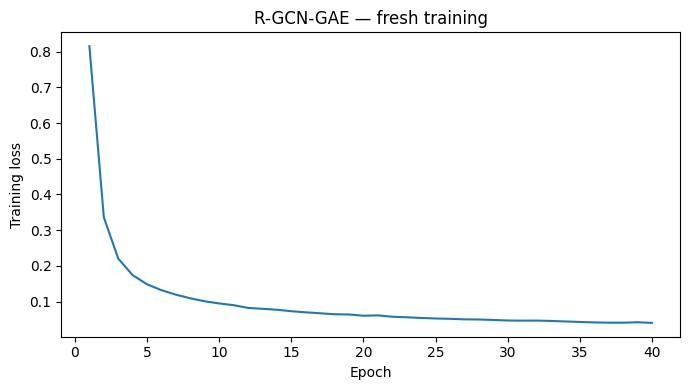

✅ FRESH training complete: 40 / 40 checkpoints saved
Epoch 40 training loss: 0.04058


In [8]:
CONFIG = dict(kind='rgcn', hidden=64, latent=32, dropout=0.1, lr=1e-3,
              weight_decay=1e-5, batch_size=128, epochs=EPOCHS, seed=SEED)
assert not any(CKPT.glob('epoch_*.pt')), 'Existing training checkpoints found; use another RUN_NAME'
net = m.build_model('rgcn', len(cols), Btr.edge_attr.shape[1], 64, 32, 0.1, REL_COLS)
config = dict(kind='rgcn', f_in=len(cols), e_dim=Btr.edge_attr.shape[1],
              hidden=64, latent=32, dropout=0.1, rel_cols=REL_COLS, rel_names=REL_NAMES, setting='nocomp',
              cols=[int(c) for c in cols], seed=SEED)
print('Starting fresh R-GCN-GAE training: 40 epochs (NORMAL ONLY)')
training_log = m.train_epochs(net, Btr, cols, device, EPOCHS,
                              CONFIG['lr'], CONFIG['weight_decay'],
                              CONFIG['batch_size'], SEED, str(CKPT), config)
training_log.to_csv(TRAIN_DIR / 'training_log.csv', index=False)
with open(TRAIN_DIR / 'configuration.json','w') as f:
    json.dump({'model':'R-GCN-GAE','dataset_split':'Approach B',
               'input_features':int(len(cols)), 'relations':REL_NAMES, 'train_graphs':int(Btr.n),
               'pooling':'mean','training_hyperparameters':CONFIG,
               'train_dataset_path':str(paths['train'])},f,indent=2)
plt.figure(figsize=(7,4))
plt.plot(training_log.epoch, training_log.train_loss)
plt.xlabel('Epoch'); plt.ylabel('Training loss'); plt.title('R-GCN-GAE — fresh training')
plt.tight_layout(); plt.savefig(TRAIN_DIR / 'training_loss.png',dpi=160); plt.show()
ckfiles = sorted(CKPT.glob('epoch_*.pt'))
assert len(ckfiles)==40 and all((CKPT/f'epoch_{ep:03d}.pt').exists() for ep in range(1,41))
print('✅ FRESH training complete: 40 / 40 checkpoints saved')
print('Epoch 40 training loss:',round(float(training_log.train_loss.iloc[-1]),6))


## 4. Approach B Validation — choose checkpoint from B validation only

Checkpoint selection uses **only the 722 normal B validation graphs** (not Approach A validation scores), avoiding the cross-approach checkpoint-selection leak. This selection does NOT consult the B test datasets.

epoch 5 validation loss 0.121297
epoch 10 validation loss 0.079903
epoch 15 validation loss 0.060181
epoch 20 validation loss 0.053927
epoch 25 validation loss 0.043605
epoch 30 validation loss 0.03947
epoch 35 validation loss 0.035796
epoch 40 validation loss 0.03282
B validation selected epoch: 40


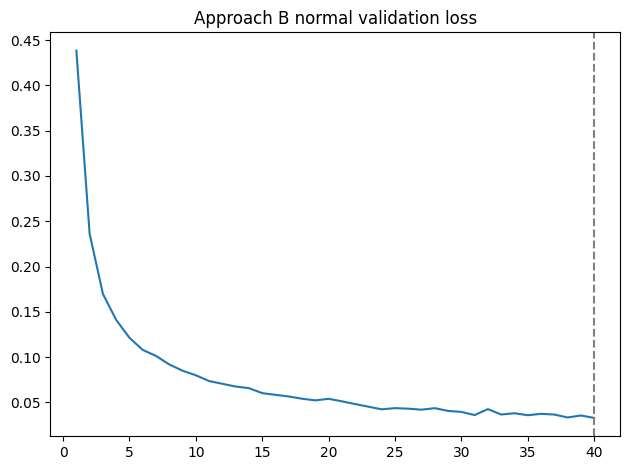

In [9]:
def subset_bucket(b,idx):
    # Materialize an independent bucket containing selected complete graphs
    idx=np.asarray(idx,dtype=np.int64)
    out=u.Bucket.__new__(u.Bucket)
    out.feature_names=b.feature_names;out.feature_groups=b.feature_groups;out.edge_feature_names=b.edge_feature_names
    xs=[];eis=[];eas=[];labels=[];np_ptr=[0];ep_ptr=[0]
    for i in idx:
        n0,n1=b.node_ptr[i:i+2];e0,e1=b.edge_ptr[i:i+2]
        xs.append(b.x[n0:n1]);eis.append(b.edge_index[:,e0:e1]);eas.append(b.edge_attr[e0:e1]);labels.append(b.node_label[n0:n1]);np_ptr.append(np_ptr[-1]+n1-n0);ep_ptr.append(ep_ptr[-1]+e1-e0)
    out.x=np.concatenate(xs);out.edge_index=np.concatenate(eis,axis=1);out.edge_attr=np.concatenate(eas);out.node_label=np.concatenate(labels)
    out.node_ptr=np.array(np_ptr,dtype=np.int64);out.edge_ptr=np.array(ep_ptr,dtype=np.int64)
    out.scenario_id=b.scenario_id[idx];out.is_attack=b.is_attack[idx];out.n=len(idx)
    out.n_nodes=np.diff(out.node_ptr);out.n_edges=np.diff(out.edge_ptr)
    return out
Vnorm=subset_bucket(Bv,np.flatnonzero(Bv.is_attack==0))
val_losses=[]
for ep in range(1,41):
    model,cfg=m.load_checkpoint(str(CKPT/f'epoch_{ep:03d}.pt'),device)
    assert cfg['f_in']==len(cols) and cfg['e_dim']==Btr.edge_attr.shape[1]
    assert np.array_equal(np.array(cfg['cols'],dtype=int),cols),'Checkpoint feature order mismatch'
    loss=m.eval_loss(model,Vnorm,cols,device,batch_size=256,seed=2024)
    val_losses.append({'epoch':ep,'normal_validation_loss':loss})
    if ep%5==0: print('epoch',ep,'validation loss',round(loss,6))
VL=pd.DataFrame(val_losses);VL.to_csv(VAL_DIR/'epoch_validation_losses.csv',index=False)
best_epoch=int(VL.loc[VL.normal_validation_loss.idxmin(),'epoch'])
print('B validation selected epoch:',best_epoch)
model,cfg=m.load_checkpoint(str(CKPT/f'epoch_{best_epoch:03d}.pt'),device)
plt.plot(VL.epoch,VL.normal_validation_loss);plt.axvline(best_epoch,ls='--',color='gray');plt.title('Approach B normal validation loss');plt.tight_layout(); plt.savefig(VAL_DIR/'epoch_validation_loss.png',dpi=160); plt.show()

## 5. Approach B Validation — select anomaly scoring method and threshold

Candidate scores: `recon_total`, `node_mean`, `node_max`, `edge_mean`, `edge_max`, `knn_embedding`. **Only B validation labels** are used to pick method and threshold. Default goal: maximize B validation F1 while keeping validation FPR ≤ 5%.

**Output:** Each scoring method is shown in a percentage-formatted validation table. The threshold is shown separately.


In [10]:
# Display helper: formatting only — does not affect threshold selection or model scores.
def show_metric_table(df, title, score_column=None):
    cols = ['accuracy','precision','recall','f1','auc','pr_auc','fpr','specificity']
    names = {'accuracy':'Accuracy','precision':'Precision','recall':'Recall',
             'f1':'F1-Score','auc':'ROC-AUC','pr_auc':'PR-AUC',
             'fpr':'False Positive Rate','specificity':'Specificity'}
    display_cols = ([score_column] if score_column else []) + [c for c in cols if c in df.columns]
    table = df[display_cols].copy().rename(columns=names)
    for c in table.columns:
        if c != score_column:
            table[c] = table[c].map(lambda x: f'{float(x)*100:.2f}%')
    print(title)
    display(table)

S_tr=m.score_bucket(model,Btr,cols,device,batch_size=256)
S_va=m.score_bucket(model,Bv,cols,device,batch_size=256)
knn=u.KNNScorer(S_tr['emb'],k=KNN_K)
S_va['graph']['knn_embedding']=knn.score(S_va['emb'])
variants=['recon_total','node_mean','node_max','edge_mean','edge_max','knn_embedding']
vm=(Bv.is_attack==0)

# At most 5% normal validation false alarms. Threshold candidates use normal-only
# observed score boundaries, so FPR has an exact, auditable interpretation.
selection=[]
for v in variants:
    n=S_va['graph'].loc[vm,v].to_numpy();a=S_va['graph'].loc[~vm,v].to_numpy()
    cand=np.unique(np.r_[n,np.percentile(n,95)])
    rows=[]
    for threshold in cand:
        met=u.metrics_at(n,a,float(threshold))
        if met['fpr']<=MAX_VALIDATION_FPR+1e-12:
            rows.append((met['f1'],met['recall'],-met['fpr'],float(threshold),met))
    assert rows, f'No valid threshold for {v}'
    winner=max(rows,key=lambda r:(r[0],r[1],r[2]))
    selection.append({'score':v,'threshold':winner[3],**winner[4]})
VRESULT=pd.DataFrame(selection).sort_values(['f1','recall','auc'],ascending=False).reset_index(drop=True)
print('=== Approach B Validation — scoring methods (percent) ===')
show_metric_table(VRESULT, 'Validation metrics (higher is better except False Positive Rate)', score_column='score')
print('Threshold for each candidate method:')
display(VRESULT[['score','threshold']].rename(columns={'score':'Scoring Method','threshold':'Anomaly Threshold'}).round(6))
VRESULT.to_csv(VAL_DIR/'score_comparison.csv',index=False)
chosen=VRESULT.iloc[0]
main_score=str(chosen['score']);threshold=float(chosen['threshold'])
print('LOCKED BEFORE TEST: epoch',best_epoch,'score',main_score,'threshold',threshold)

locked={'training_origin':'fresh_training_approach_b_normal_only','validation':'approach_b_mixed','selected_epoch':best_epoch,
 'score':main_score,'threshold':threshold,'max_validation_fpr':MAX_VALIDATION_FPR,'knn_k':KNN_K,
 'checkpoint_path':str(CKPT/f'epoch_{best_epoch:03d}.pt'),'validation_metrics':{k:float(chosen[k]) for k in ['accuracy','precision','recall','f1','auc','fpr']},
 'test_exposure_note':'Exploratory: source scenarios were previously inspected in Approach A; test predictions never used for the current threshold selection.'}
with open(VAL_DIR/'locked_selection.json','w') as f:json.dump(locked,f,indent=2)
print('Selection locked and saved to',VAL_DIR/'locked_selection.json')


=== Approach B Validation — scoring methods (percent) ===
Validation metrics (higher is better except False Positive Rate)


,score,Accuracy,Precision,Recall,F1-Score,ROC-AUC,False Positive Rate
0,knn_embedding,84.04%,93.78%,67.81%,78.71%,87.42%,3.46%
1,node_mean,78.17%,89.68%,56.29%,69.17%,89.56%,4.99%
2,node_max,78.01%,89.86%,55.76%,68.81%,86.66%,4.85%
3,recon_total,73.08%,87.32%,44.60%,59.05%,81.60%,4.99%
4,edge_mean,69.01%,84.48%,35.25%,49.75%,70.48%,4.99%
5,edge_max,66.43%,81.91%,29.32%,43.18%,67.96%,4.99%


Threshold for each candidate method:


,Scoring Method,Anomaly Threshold
0,knn_embedding,2.582520
1,node_mean,0.020127
2,node_max,0.042573
3,recon_total,0.053861
4,edge_mean,0.038754
5,edge_max,0.195454


LOCKED BEFORE TEST: epoch 40 score knn_embedding threshold 2.5825197985552437
Selection locked and saved to /content/drive/MyDrive/GNN/Models/RGCN/validation/locked_selection.json


In [11]:
# Approach B VALIDATION — selected method summary (display only; no reselection)
from sklearn.metrics import average_precision_score
_val_normal = S_va['graph'].loc[vm, main_score].to_numpy()
_val_attack = S_va['graph'].loc[~vm, main_score].to_numpy()
_val_metrics = u.metrics_at(_val_normal, _val_attack, threshold)
_val_y = np.r_[np.zeros(len(_val_normal), dtype=int), np.ones(len(_val_attack), dtype=int)]
_val_scores = np.r_[_val_normal, _val_attack]
_val_metrics['pr_auc'] = float(average_precision_score(_val_y, _val_scores))
_val_metrics['specificity'] = 1.0 - _val_metrics['fpr']
print('=== APPROACH B VALIDATION — SELECTED METHOD ===')
print(f'Epoch: {best_epoch} | Scoring method: {main_score} | Threshold: {threshold:.6f}')
_val_labels = {'accuracy':'Accuracy', 'precision':'Precision', 'recall':'Recall',
               'f1':'F1-Score', 'auc':'ROC-AUC', 'pr_auc':'PR-AUC',
               'fpr':'False Positive Rate', 'specificity':'Specificity'}
_val_table = pd.DataFrame([{'Metric': label, 'Validation Result': f'{_val_metrics[key]*100:.2f}%'}
                           for key, label in _val_labels.items()])
display(_val_table)
print('=== VALIDATION CONFUSION MATRIX — GRAPH COUNTS ===')
_val_cm = pd.DataFrame([[_val_metrics['tn'], _val_metrics['fp']],
                        [_val_metrics['fn'], _val_metrics['tp']]],
                       index=['Actual Normal', 'Actual Attack'],
                       columns=['Predicted Normal', 'Predicted Attack'])
display(_val_cm)
print('Validation graphs:',len(_val_y),'| Normal:',len(_val_normal),'| Attack:',len(_val_attack))
# These are in-sample validation metrics used for selection; not an independent test.

# Save individual validation graph scores for future *validation-only* diagnostics.
_val_scores_frame = S_va['graph'].copy()
_val_scores_frame.insert(0,'scenario_id',Bv.scenario_id)
_val_scores_frame.insert(1,'is_attack',Bv.is_attack)
_val_scores_frame['predicted_attack'] = (_val_scores_frame[main_score].to_numpy() > threshold).astype(int)
_val_scores_frame.to_csv(VAL_DIR/'per_graph_validation_scores.csv',index=False)
_val_table.to_csv(VAL_DIR/'selected_metrics.csv',index=False)
_val_cm.to_csv(VAL_DIR/'confusion_matrix.csv')
print('✅ Validation reports saved in',VAL_DIR)


=== APPROACH B VALIDATION — SELECTED METHOD ===
Epoch: 40 | Scoring method: knn_embedding | Threshold: 2.582520


,Metric,Validation Result
0,Accuracy,84.04%
1,Precision,93.78%
2,Recall,67.81%
3,F1-Score,78.71%
4,ROC-AUC,87.42%
5,PR-AUC,88.56%
6,False Positive Rate,3.46%
7,Specificity,96.54%


=== VALIDATION CONFUSION MATRIX — GRAPH COUNTS ===


,Predicted Normal,Predicted Attack
Actual Normal,697,25
Actual Attack,179,377


Validation graphs: 1278 | Normal: 722 | Attack: 556
✅ Validation reports saved in /content/drive/MyDrive/GNN/Models/RGCN/validation


## 6. Approach B Testing — apply the LOCKED selection exactly once

This section only uses the selected epoch, score and threshold. **Never change these based on test scores.** The test has 1,112 normal and 1,444 attack graphs. Note that this dataset has been indirectly exposed through earlier Approach A experiments, so use the results as exploratory research evidence, not an untouched blind test.

**Output:** Test performance is shown as a percentage-formatted metrics table and a 2×2 confusion matrix with actual graph counts.


In [12]:
assert (VAL_DIR/'locked_selection.json').is_file(),'Run B validation first'
with open(VAL_DIR/'locked_selection.json') as f:locked_again=json.load(f)
assert locked_again['selected_epoch']==best_epoch and locked_again['score']==main_score and locked_again['threshold']==threshold
S_n=m.score_bucket(model,Bn,cols,device,batch_size=256)
S_a=m.score_bucket(model,Ba,cols,device,batch_size=256)
S_n['graph']['knn_embedding']=knn.score(S_n['emb'])
S_a['graph']['knn_embedding']=knn.score(S_a['emb'])
normal=S_n['graph'][main_score].to_numpy();attack=S_a['graph'][main_score].to_numpy()
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score
met=u.metrics_at(normal,attack,threshold)
y=np.r_[np.zeros(len(normal),dtype=int),np.ones(len(attack),dtype=int)]
scores=np.r_[normal,attack];pred=(scores>threshold).astype(int)
met['pr_auc']=float(average_precision_score(y,scores));met['specificity']=1-met['fpr']
print('=== APPROACH B TEST — LOCKED METHOD ===')
print('Checkpoint epoch:',best_epoch,'| score:',main_score,'| threshold:',round(threshold,6))
show_metric_table(pd.DataFrame([met]), 'Final Approach B test metrics (percent)')
print('=== CONFUSION MATRIX — GRAPH COUNTS ===')
cm = pd.DataFrame([[met['tn'], met['fp']], [met['fn'], met['tp']]],
                  index=['Actual Normal','Actual Attack'],
                  columns=['Predicted Normal','Predicted Attack'])
display(cm)
print('TP = detected attacks | FN = missed attacks | FP = false alarms | TN = correctly classified normal graphs')
print(f"Test total: {len(y):,} graphs ({len(normal):,} normal, {len(attack):,} attack)")
pd.DataFrame([{'epoch':best_epoch,'selected_score':main_score,**met}]).to_csv(TEST_DIR/'locked_test_results.csv',index=False)
pd.DataFrame({'scenario_id':np.r_[Bn.scenario_id,Ba.scenario_id], 'true_label':y,'anomaly_score':scores,'predicted_attack':pred}).to_csv(TEST_DIR/'scenario_predictions.csv',index=False)
# Comparison of other scoring methods for DIAGNOSTIC purposes only. They are NOT selected on test.
extra=[]
for v in variants:
 n=S_n['graph'][v].to_numpy();a=S_a['graph'][v].to_numpy()
 extra.append({'score':v,'test_roc_auc_diagnostic_only':u.auc(n,a)})
display(pd.DataFrame(extra).round(4))
cm.to_csv(TEST_DIR/'confusion_matrix.csv')
# Save machine- and human-readable testing metrics separately
pd.DataFrame([{'Metric':k,'Value (%)':round(float(met[k])*100,2)} for k in
              ['accuracy','precision','recall','f1','auc','pr_auc','fpr','specificity']]).to_csv(TEST_DIR/'selected_metrics_pretty.csv',index=False)
print('✅ Testing reports saved at',TEST_DIR)
print('✅ A-to-Z run finished. All outputs at',OUT)

=== APPROACH B TEST — LOCKED METHOD ===
Checkpoint epoch: 40 | score: knn_embedding | threshold: 2.58252
Final Approach B test metrics (percent)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,False Positive Rate,Specificity
0,78.91%,95.11%,66.07%,77.97%,86.21%,91.29%,4.41%,95.59%


=== CONFUSION MATRIX — GRAPH COUNTS ===


,Predicted Normal,Predicted Attack
Actual Normal,1063,49
Actual Attack,490,954


TP = detected attacks | FN = missed attacks | FP = false alarms | TN = correctly classified normal graphs
Test total: 2,556 graphs (1,112 normal, 1,444 attack)


,score,test_roc_auc_diagnostic_only
0,recon_total,0.8245
1,node_mean,0.8995
2,node_max,0.8674
3,edge_mean,0.7162
4,edge_max,0.6921
5,knn_embedding,0.8621


✅ Testing reports saved at /content/drive/MyDrive/GNN/Models/RGCN/testing
✅ A-to-Z run finished. All outputs at /content/drive/MyDrive/GNN/Models/RGCN


## 7. FINAL RESULTS AND FILE GUIDE

After **Run all**, use these folders in Google Drive:

- `training/`: 40 fresh epoch checkpoints, training log, settings JSON, loss curve.
- `validation/`: validation loss per epoch, score comparison, chosen epoch/score/threshold, **selected metrics + confusion matrix**, and **individual validation graph scores**.
- `testing/`: **final metric summary + confusion matrix**, locked test results, and scenario predictions.
- `reports/`: reserved for a project report and model-comparison export.

**Which numbers do I report?** The **Testing selected-metrics table** is the measured result for this particular complete run. Validation metrics document how settings were selected. Do **not** assume this fresh run will exactly match the previously reported 77.70% accuracy; training is rerun and validation may select a different epoch.

**Scientific limitations:** These Approach B graphs originate from previously explored source scenarios, so this experiment is exploratory, not a genuinely untouched independent final test. High graph-level anomaly classification scores alone do not verify true lateral-movement path reconstruction. `nocomp` means Host+IoT graph telemetry with the eight simulated component score features excluded; integration of real C1/C2 model outputs must be separately evaluated. Do not select thresholds or architectures from test scores.
